# 01 — Data Collection & Exploration

**Mục đích:** xác minh provenance, schema, chất lượng và các đơn vị quan sát trước khi nhóm làm Q1–Q5. Dữ liệu raw được giữ nguyên; mọi biến đổi bên dưới chỉ áp dụng lên bản làm việc.

### Phân công

- **Tiết Trọng Khiêm — 24127058:** Data Card, nguồn và license; Q1–Q2.
- **Lê Kiến Quốc — 24127115:** schema, data quality, preprocessing; Q3–Q4.
- **Trịnh Tấn Phát — 24127485:** dataset bổ trợ và Q5; Q6 thuộc bạn nhưng nằm ngoài phạm vi notebook 01–02 của change này.

Các kết quả tính toán bên dưới là bằng chứng để nhóm tự giải thích. Mỗi thành viên tự viết phần kết luận và reflection theo quy định môn học.

## 1. Data Card & provenance

### 1.1 Chủ đề, đơn vị và người dùng

PhishVN là bộ dữ liệu URL có dấu thời gian, nhãn phishing/benign trong bối cảnh Việt Nam. Một hàng trong `vn_compphish.csv` là một URL; hàng không đại diện cho người dùng hay tin nhắn. Kết quả có thể hỗ trợ đội an toàn thông tin ưu tiên URL để rà soát thêm. Nhãn phishing của nguồn được kế thừa từ các feed chống lừa đảo, nên không đồng nghĩa mọi trường hợp đều là credential phishing.

### 1.2 Nguồn, phiên bản và giấy phép

| Thuộc tính | Ghi nhận từ nguồn |
|---|---|
| Dataset | [PhishVN, Mendeley Data version 4](https://data.mendeley.com/datasets/b97hxbxtpd/4), DOI `10.17632/b97hxbxtpd.4` |
| Contributor | Thai Nguyen Vu, University of Transport and Communications — Ho Chi Minh City Campus |
| Published | 18 Aug 2026; version 4 mô tả là cập nhật tài liệu, các data files không đổi so với v3 |
| License | CC BY 4.0; cần ghi attribution cho dataset và upstream sources |
| Open archive đã kiểm tra | `PhishVN_v3.1.0_open.zip`; manifest SHA-256 của ba CSV trong archive khớp nội dung |
| Upstream phishing sources | NCSC Tin Nhiem Mang, ChongLuaDao, OpenPhish |
| Upstream benign sources | Trusted-organisation registry và Tranco |
| Thời gian | Phishing first-seen dates trong tài liệu nguồn: 2020-02-08 đến 2025-02-18; phần benign registry/top-list phần lớn không có event date |
| Thu thập | Scraping có giới hạn tốc độ và tôn trọng robots; nguồn upstream có coverage/bias khác nhau |

Dataset nguồn ghi 53,116 URL: 18,997 bản ghi gold/silver và 34,119 bản ghi bronze. Dữ liệu bronze là community/feed expansion; tài liệu nguồn báo mức bất định nhãn cao hơn ở nhóm này. Các con số thực tế của hai file được đọc lại ở phần EDA bên dưới.

`abuse_type.csv` là side table rule-derived dành cho lớp phishing. Tài liệu datasheet mô tả khóa là URL và giải thích `unknown` là giá trị có chủ đích khi quy tắc không suy ra được loại abuse. Đây không phải nhãn thay thế cho `label`.

### 1.3 Related work và phê duyệt

- Bài companion đã xuất bản: Vu, Thai Nguyen (2026), *PhishVN: A time-stamped Vietnamese URL phishing dataset with impersonation-scenario labels and confidence tiers*, Data in Brief 68, 113195, [DOI](https://doi.org/10.1016/j.dib.2026.113195).
- Tác giả có [repository công khai về PhishVN và baselines](https://github.com/vuthainguyen1602/phishvn), trong đó có [notebooks công khai](https://github.com/vuthainguyen1602/phishvn/tree/master/notebooks), tài liệu dataset, quy trình xử lý, benchmark/model baselines và các audit. Bài này dùng repo làm related work; không sao chép câu hỏi hoặc workflow Q1–Q5. Q6 của nhóm cũng nằm trong vùng chủ đề baseline/modeling công khai, nên chủ sở hữu cần nêu rõ khác biệt của prediction target, split, feature hoặc mục tiêu phân tích.
- Đây là rà soát mục tiêu ban đầu, không phải tìm kiếm tài liệu có hệ thống. Nhóm vẫn cần kiểm tra thêm public notebooks/analyses trước khi nộp và ghi lại phê duyệt dataset của giảng viên nếu đã có.

### 1.4 Động lực chọn dữ liệu

`[Nhóm tự ghi vì sao chọn đề tài/dataset và ai là người sẽ dùng kết quả.]`


## 2. Setup, schema và quy ước đọc dữ liệu

Nguồn phát hành mô tả `vn_compphish.csv` là 21 lexical features cùng label/split. Header trong archive đang dùng có 28 cột, bao gồm thêm `url`, `dom`, `tld`, `is_https` và `tier`. Notebook ghi schema quan sát được, không ép file về mô tả rút gọn.

`label` trong file chính là số: mapping được đối chiếu với bảng URL đầy đủ trong cùng archive: `1 = phishing`, `0 = benign`. `split` có `train`, `val`, `test`; `tier` có `gold`, `silver`, `bronze`. `is_https` được giữ để phục vụ câu hỏi Q2 nhưng tài liệu nguồn cảnh báo đây là collection artifact, không được xem như feature dự đoán độc lập hoặc bằng chứng nhân quả.

Tạo môi trường `phishguard-vn` từ `environment.yml`, mở Jupyter tại thư mục gốc repo và chạy notebook theo thứ tự trong README. Hai CSV dưới đây được load ở chế độ chỉ đọc từ `data/raw/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

starts = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in starts if (p / "environment.yml").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate repository root containing environment.yml.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_io import category_counts, duplicate_summary, load_raw_csv, missing_summary
from src.url_utils import hostname_from_url, normalize_url_key

main_raw = load_raw_csv("vn_compphish.csv")
aux_raw = load_raw_csv("abuse_type.csv")
# Work only on copies. The raw CSVs are never changed by this notebook.
main = main_raw.copy()
aux = aux_raw.copy()
LABEL_NAMES = {0: "benign", 1: "phishing"}
main["label_name"] = main["label"].map(LABEL_NAMES)
print(f"Main dataset: {main.shape[0]:,} rows × {main_raw.shape[1]} columns")
print(f"Auxiliary dataset: {aux.shape[0]:,} rows × {aux_raw.shape[1]} columns")
print("Raw files loaded from:", PROJECT_ROOT / "data" / "raw")

Main dataset: 53,116 rows × 28 columns
Auxiliary dataset: 36,706 rows × 3 columns
Raw files loaded from: /Users/Mac/Downloads/Study/codeDS/data/raw


## 3. Main dataset — structure and quality

The profile reports every column's dtype, missing values and distinct-value count. Category tables retain missing values as an explicit category. Exact URL duplicates and repeated domains are counted separately because later questions use different units of analysis.

In [2]:
main_profile = missing_summary(main_raw)
display(main_profile)
print("Exact duplicate rows:", duplicate_summary(main_raw)["duplicate_rows"])
print("Duplicate URL rows:", duplicate_summary(main_raw, key="url")["duplicate_key_rows"])
print("Distinct `dom` values:", main_raw["dom"].nunique(dropna=True))
print("Rows with a repeated `dom` value:", int(main_raw["dom"].duplicated(keep=False).sum()))

for column in ("label", "split", "tier", "is_https", "tld"):
    print(f"\n{column} counts")
    display(category_counts(main, column).head(15))

print("\nLabel × tier counts")
display(pd.crosstab(main["tier"], main["label_name"], margins=True))
print("\nLabel × split counts")
display(pd.crosstab(main["split"], main["label_name"], margins=True))
print("\nURL length by label (characters)")
display(main.groupby("label_name")["url_len"].describe(percentiles=[.25, .5, .75, .9]).round(2))

domain_split_counts = main.groupby("dom", dropna=True)["split"].nunique()
print("Exact `dom` values appearing in multiple splits:", int(domain_split_counts.gt(1).sum()))

# IQR fences flag distribution tails for review; they do not imply that values are errors.
numeric_columns = main_raw.select_dtypes(include="number").columns.difference(["label"], sort=False)
ratio_columns = {column for column in numeric_columns if column.endswith("_ratio")}
numeric_rows = []
for column in numeric_columns:
    values = main_raw[column].dropna()
    q1, median, q3 = values.quantile([.25, .5, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    numeric_rows.append({
        "column": column, "n": len(values), "min": values.min(), "q1": q1, "median": median,
        "q3": q3, "max": values.max(), "mean": values.mean(), "std": values.std(),
        "iqr_fence_n": int(((values < lower) | (values > upper)).sum()),
        "negative_n": int(values.lt(0).sum()),
        "ratio_outside_0_1_n": int((values.lt(0) | values.gt(1)).sum()) if column in ratio_columns else np.nan,
        "constant": values.nunique() <= 1,
    })
numeric_audit = pd.DataFrame(numeric_rows).set_index("column")
print("Numeric feature distribution and plausibility screen (label excluded):")
display(numeric_audit.round(4))
print("IQR-fence counts are screening flags only; inspect tails before any transformation.")
print("Constant numeric features:", numeric_audit.index[numeric_audit["constant"]].tolist())


,column,dtype,missing_n,missing_pct,distinct_n
0,url,str,0,0.0,53116
1,url_len,int64,0,0.0,97
2,dom,str,0,0.0,28647
3,dom_len,int64,0,0.0,45
4,is_ip,int64,0,0.0,1
5,tld,str,2,0.0,516
6,tld_len,int64,0,0.0,12
7,subdom_cnt,int64,0,0.0,6
8,letter_cnt,int64,0,0.0,80
9,digit_cnt,int64,0,0.0,40


Exact duplicate rows: 0
Duplicate URL rows: 0
Distinct `dom` values: 28647
Rows with a repeated `dom` value: 41525

label counts


,label,count,percent
0,1,36706,69.11
1,0,16410,30.89



split counts


,split,count,percent
0,train,36909,69.49
1,test,8941,16.83
2,val,7266,13.68



tier counts


... (10 outputs left out)

,count,mean,std,min,25%,50%,75%,90%,max
label_name,,,,,,,,,
benign,16410.0,18.19,7.99,4.0,12.0,16.0,24.0,30.0,70.0
phishing,36706.0,15.67,7.12,4.0,12.0,14.0,18.0,22.0,412.0


Exact `dom` values appearing in multiple splits: 0
Numeric feature distribution and plausibility screen (label excluded):


,n,min,q1,median,q3,max,mean,std,iqr_fence_n,negative_n,ratio_outside_0_1_n,constant
column,,,,,,,,,,,,
url_len,53116,4.0000,12.0000,15.0000,19.0000,412.0000,16.4454,7.4902,2757,0,NaN,False
dom_len,53116,4.0000,10.0000,13.0000,15.0000,61.0000,13.3107,4.2039,1928,0,NaN,False
is_ip,53116,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,NaN,True
tld_len,53116,0.0000,3.0000,3.0000,4.0000,12.0000,3.5024,1.3079,9595,0,NaN,False
subdom_cnt,53116,0.0000,0.0000,0.0000,1.0000,6.0000,0.5095,0.5724,20,0,NaN,False
letter_cnt,53116,2.0000,9.0000,12.0000,17.0000,316.0000,13.6776,6.7255,1079,0,NaN,False
digit_cnt,53116,0.0000,0.0000,0.0000,2.0000,79.0000,0.9446,1.9074,871,0,NaN,False
special_cnt,53116,1.0000,1.0000,2.0000,2.0000,22.0000,1.8232,0.9689,3006,0,NaN,False
eq_cnt,53116,0.0000,0.0000,0.0000,0.0000,4.0000,0.0012,0.0521,41,0,NaN,False


IQR-fence counts are screening flags only; inspect tails before any transformation.
Constant numeric features: ['is_ip']


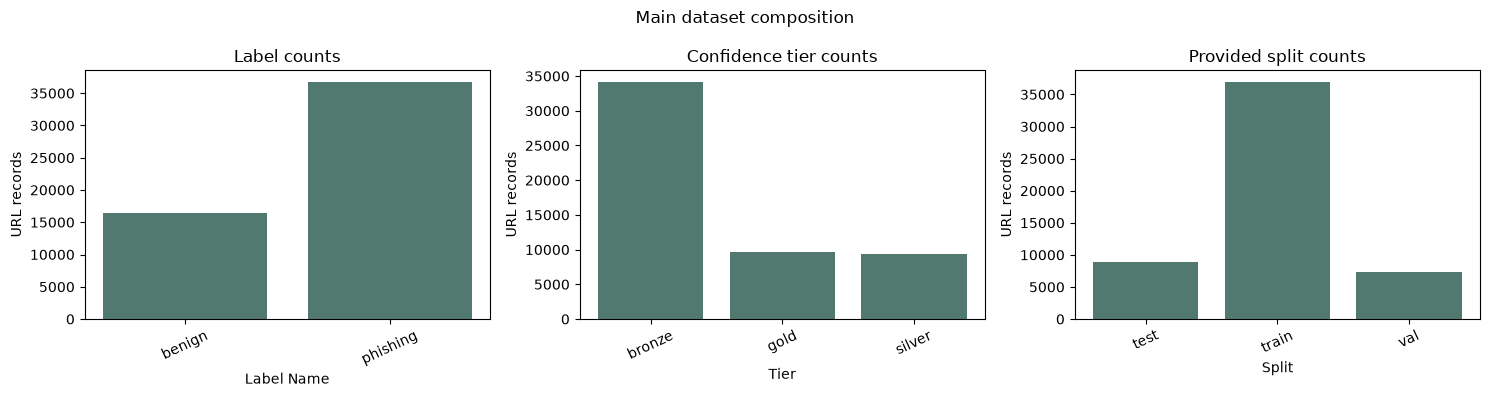

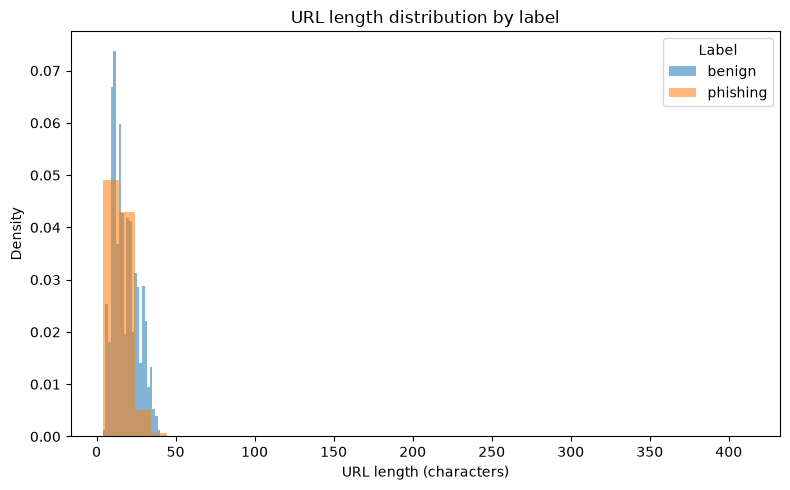

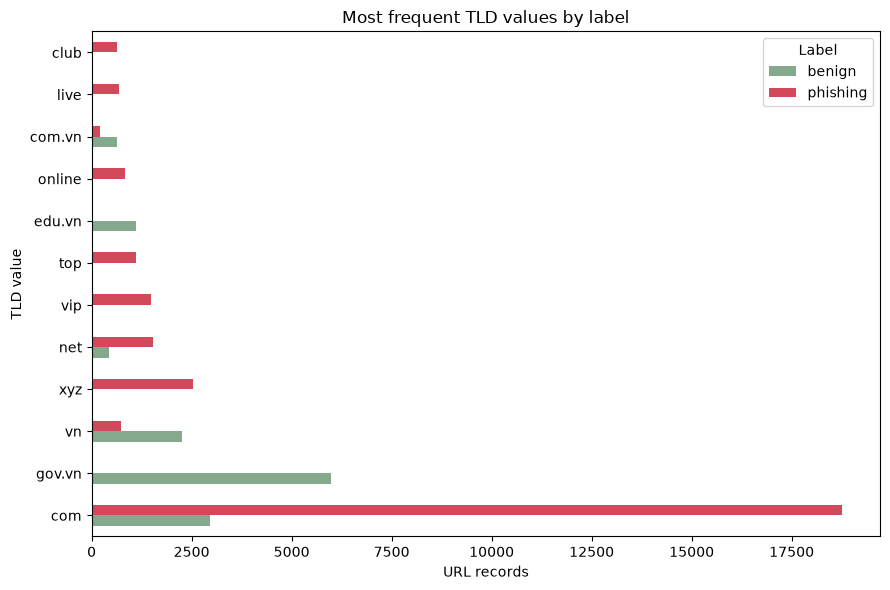

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(axes, ("label_name", "tier", "split"), ("Label counts", "Confidence tier counts", "Provided split counts")):
    counts = main[column].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color="#52796f")
    ax.set_title(title)
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("URL records")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Main dataset composition")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for label_name, group in main.groupby("label_name"):
    ax.hist(group["url_len"].dropna(), bins=40, alpha=.55, density=True, label=label_name)
ax.set_title("URL length distribution by label")
ax.set_xlabel("URL length (characters)")
ax.set_ylabel("Density")
ax.legend(title="Label")
fig.tight_layout()
plt.show()

tld_counts = main.assign(tld_plot=main["tld"].fillna("Missing")).groupby(["tld_plot", "label_name"]).size().unstack(fill_value=0)
top_tlds = tld_counts.sum(axis=1).sort_values(ascending=False).head(12).index
ax = tld_counts.loc[top_tlds].plot(kind="barh", figsize=(9, 6), color=["#84a98c", "#d1495b"])
ax.set_title("Most frequent TLD values by label")
ax.set_xlabel("URL records")
ax.set_ylabel("TLD value")
ax.legend(title="Label")
plt.tight_layout()
plt.show()

## 4. Auxiliary dataset — structure and comparison keys

`abuse_type.csv` has URL, `abuse_type`, and `rule`. Empty `rule` values accompany `unknown` in this release; they are not interpreted as missing abuse labels. The primary audit below uses the documented URL-key comparison after normalization. A separate hostname-level table derives the host from each URL and aggregates both sides before comparison. The `dom` column can be broader than the URL hostname, so it is reported separately for the domain-level question rather than silently substituted for hostname.

In [4]:
aux_profile = missing_summary(aux_raw)
display(aux_profile)
print("Exact duplicate rows:", duplicate_summary(aux_raw)["duplicate_rows"])
print("Duplicate URL-key rows:", duplicate_summary(aux_raw, key="url")["duplicate_key_rows"])
print("\nAbuse-type counts and percentages")
display(category_counts(aux, "abuse_type"))
print("\nRule counts (top 15; empty rule is shown as missing by pandas)")
display(aux["rule"].fillna("[blank]").value_counts().head(15).rename_axis("rule").to_frame("count"))

main_url_keys = main_raw["url"].map(normalize_url_key)
aux_url_keys = aux_raw["url"].map(normalize_url_key)
main_url_key_duplicates = int(main_url_keys.duplicated().sum())
aux_url_key_duplicates = int(aux_url_keys.duplicated().sum())
url_key_audit = pd.DataFrame({"url_key": main_url_keys, "label": main_raw["label"]}).merge(
    pd.DataFrame({"url_key": aux_url_keys, "abuse_type": aux_raw["abuse_type"], "rule": aux_raw["rule"]}),
    on="url_key", how="left", validate="one_to_one", indicator=True
)
print("Normalized URL-key duplicates — main / auxiliary:", main_url_key_duplicates, "/", aux_url_key_duplicates)
print("URL-key audit rows before / after:", len(main_raw), "/", len(url_key_audit))
print("URL-key audit match status:", url_key_audit["_merge"].value_counts().to_dict())
print("Matched main labels:", url_key_audit.loc[url_key_audit["_merge"].eq("both"), "label"].value_counts().to_dict())

main_hosts = pd.DataFrame({"hostname": main_raw["url"].map(hostname_from_url), "label": main_raw["label"], "tld": main_raw["tld"]}).dropna(subset=["hostname"]).groupby("hostname", as_index=False).agg(
    main_url_n=("label", "size"), main_phishing_rate=("label", "mean"), main_tld=("tld", "first")
)
aux_hosts = pd.DataFrame({"hostname": aux_raw["url"].map(hostname_from_url), "abuse_type": aux_raw["abuse_type"]}).dropna(subset=["hostname"]).groupby("hostname", as_index=False).agg(
    auxiliary_url_n=("abuse_type", "size"), abuse_type_n=("abuse_type", "nunique")
)
host_join_audit = main_hosts.merge(aux_hosts, on="hostname", how="outer", validate="one_to_one", indicator=True)
print("URL-parsed hostnames / distinct `dom` values:", main_raw["url"].map(hostname_from_url).nunique(), "/", main_raw["dom"].nunique())
print("Repeated URL-parsed hostnames / repeated `dom` values:", int(main_raw["url"].map(hostname_from_url).value_counts().gt(1).sum()), "/", int(main_raw["dom"].value_counts().gt(1).sum()))
print("Hostname-level groups before / after:", len(main_hosts), "+", len(aux_hosts), "/", len(host_join_audit))
print("Hostname-level match status:", host_join_audit["_merge"].value_counts().to_dict())

,column,dtype,missing_n,missing_pct,distinct_n
0,url,str,0,0.00,36706
1,abuse_type,str,0,0.00,6
2,rule,str,32666,88.99,48


Exact duplicate rows: 0
Duplicate URL-key rows: 0

Abuse-type counts and percentages


,abuse_type,count,percent
0,unknown,32666,88.99
1,brand_impersonation,3364,9.16
2,gambling,337,0.92
3,investment,284,0.77
4,betting_stream,40,0.11
5,adult,15,0.04



Rule counts (top 15; empty rule is shown as missing by pandas)


,count
rule,
[blank],32666
scenario=bank,1402
scenario=ecommerce,1290
scenario=gaming,407
scenario=social,143
token=go88,141
token=coin,123
scenario=delivery,45
token=crypto,43


Normalized URL-key duplicates — main / auxiliary: 0 / 0
URL-key audit rows before / after: 53116 / 53116
URL-key audit match status: {'both': 36706, 'left_only': 16410, 'right_only': 0}
Matched main labels: {1: 36706}


URL-parsed hostnames / distinct `dom` values: 53042 / 28647
Repeated URL-parsed hostnames / repeated `dom` values: 45 / 17056
Hostname-level groups before / after: 53042 + 36657 / 53042
Hostname-level match status: {'both': 36657, 'left_only': 16385, 'right_only': 0}


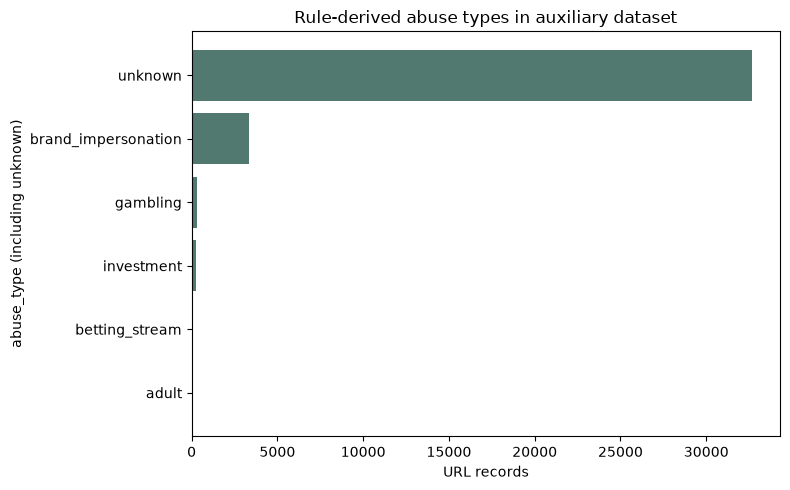

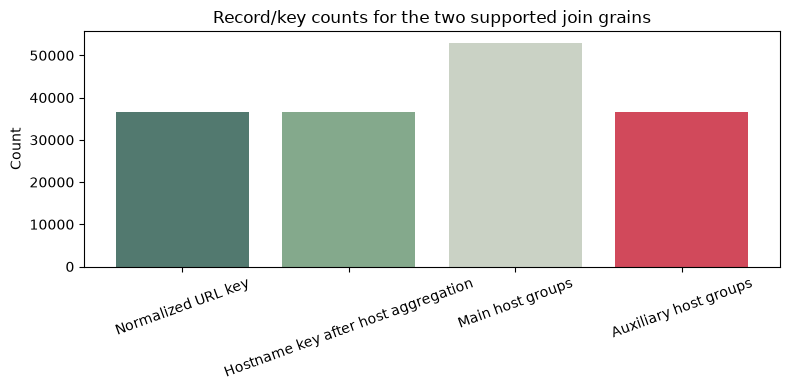

In [5]:
aux_counts = aux["abuse_type"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(aux_counts.index.astype(str), aux_counts.values, color="#52796f")
ax.set_title("Rule-derived abuse types in auxiliary dataset")
ax.set_xlabel("URL records")
ax.set_ylabel("abuse_type (including unknown)")
fig.tight_layout()
plt.show()

match_counts = pd.Series({
    "Normalized URL key": int(url_key_audit["_merge"].eq("both").sum()),
    "Hostname key after host aggregation": int(host_join_audit["_merge"].eq("both").sum()),
    "Main host groups": len(main_hosts),
    "Auxiliary host groups": len(aux_hosts),
})
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(match_counts.index, match_counts.values, color=["#52796f", "#84a98c", "#cad2c5", "#d1495b"])
ax.set_title("Record/key counts for the two supported join grains")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()

## 5. Preprocessing decisions for group review

The raw CSVs remain immutable. The notebook uses in-memory copies and no row filtering during the overview. Numeric label mapping is retained as a derived display field only.

| Issue | Evidence from this release | Proposed handling for analysis | Row counts |
|---|---|---|---|
| Missing TLD | Two rows have missing `tld` | Keep as explicit `Missing` group where TLD is analyzed; do not drop silently | 53,116 → 53,116 |
| Repeated hostname/domain | URL is unique; URL-parsed hostname and `dom` have different cardinalities | Use URL-parsed hostname for Q4; report `dom`-level grouping as a separate coarser sensitivity; aggregate before Q5 host comparison | Host counts reported in code |
| Empty `rule` with `unknown` | Source defines `unknown` as by design; corresponding rule text is blank | Preserve `unknown`; do not interpret blank rule as a label or drop it | 36,706 → 36,706 |
| Q5 key | Datasheet describes URL key; exact normalized URL and host-level match have separate cardinalities | Report URL-level primary comparison and host-level comparison after aggregation; inspect any conflicts | Counts printed above |
| HTTPS | Source identifies `is_https` as a collection artifact | Use only for Q2 association, with caveat; exclude from ML features | No filtering in this notebook |

### 5.1. Group-authored exploration summary

1. `[Thành viên 2: ghi quan sát có số liệu và giải thích ý nghĩa.]`
2. `[Thành viên 2: ghi vấn đề chất lượng dữ liệu và tác động.]`
3. `[Thành viên 3: ghi kết quả audit khóa/đối chiếu auxiliary.]`
4. `[Có thể bổ sung quan sát.]`
5. `[Có thể bổ sung quan sát.]`

### 5.2. Cần xác nhận trước khi chốt phân tích

- `[Nhóm xác nhận cách dùng tier khi báo cáo pooled results.]`
- `[Nhóm xác nhận ngưỡng gộp TLD hiếm và nhóm chiều dài URL.]`
- `[Nhóm xác nhận Q5 dùng URL-level làm phân tích chính và hostname-level làm robustness.]`
- `[Thành viên 1 bổ sung trạng thái phê duyệt dataset và related-work search.]`